# Computer Vision Ödevi: Fashion-MNIST Veri Seti ile CNN Tabanlı Kıyafet Sınıflandırma ve Web Uygulaması

* **Öğrenci Numarası:** `23120205011`
* **Problem / Görev:** Görüntü Sınıflandırma (Image Classification - 10 Sınıf)
* **Model Mimarisi:** Convolutional Neural Network (CNN)
* **Veri Seti:** Fashion-MNIST ($28 \times 28$ Gri Seviye)
* **Uygulama (Deployment):** Gradio Web Arayüzü

---

### Ödev Kapsamı
1. **Veri Hazırlığı:** Fashion-MNIST veri setinin indirilmesi; Train (50.000), Validation (10.000) ve Test (10.000) kümelerine ayrılması.
2. **CNN Modelleri ve Karşılaştırma:** Sıfırdan tasarlanan Temel CNN ve Geliştirilmiş CNN (BatchNorm + Dropout) modellerinin eğitimi ve kıyaslanması.
3. **Performans Değerlendirmesi:** Accuracy, Precision, Recall, F1-score, Karmaşıklık Matrisi (Confusion Matrix), Eğitim Süresi ve Tek Görüntü Tahmin (Inference) Süresi raporlaması.
4. **Gerçek Görüntülerle Test:** Telefonla çekilen 5 farklı kıyafet/ayakkabı/çanta fotoğrafının Fashion-MNIST formatına dönüştürülerek test edilmesi ve yorumlanması.
5. **Canlı Uygulama (Gradio):** Kullanıcının fotoğraf yükleyip anlık sınıf tahmini alabileceği etkileşimli arayüz.


In [1]:
import os
import time
import glob
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import scipy.ndimage as ndimage
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

# ============================ GENEL AYARLAR ============================
STUDENT_NO = "23120205011"
SEED       = 42
EPOCHS     = 6
BATCH_SIZE = 128

# Fashion-MNIST ortalama ve standart sapma değerleri
FMNIST_MEAN = 0.2860
FMNIST_STD  = 0.3530

CLASS_NAMES_TR = [
    "0: Tişört/Üst (T-shirt/top)",
    "1: Pantolon (Trouser)",
    "2: Kazak (Pullover)",
    "3: Elbise (Dress)",
    "4: Mont/Kaban (Coat)",
    "5: Sandalet (Sandal)",
    "6: Gömlek (Shirt)",
    "7: Spor Ayakkabı (Sneaker)",
    "8: Çanta (Bag)",
    "9: Bot (Ankle boot)"
]

CLASS_NAMES_SHORT = [
    "Tişört", "Pantolon", "Kazak", "Elbise", "Mont",
    "Sandalet", "Gömlek", "Spor Ayakkabı", "Çanta", "Bot"
]

OUT_DIR    = "results"
PHOTOS_DIR = "my_photos"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(PHOTOS_DIR, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan Hesaplama Cihazı: {device}")


Kullanılan Hesaplama Cihazı: cpu


## 1. Veri Setinin İndirilmesi ve Kümelerin Ayrılması

Fashion-MNIST veri seti 10 farklı giyim kategorisinden oluşan toplam 70.000 adet $28 \times 28$ gri tonlamalı görüntü içerir:
* **Eğitim (Train) Kümesi:** 50.000 örnek
* **Doğrulama (Validation) Kümesi:** 10.000 örnek (Train ile kesişmez; hiperparametre ve model seçimi için)
* **Test Kümesi:** 10.000 örnek (Sadece en sonda nihai modelin başarımını ölçmek için)


100%|██████████| 26.4M/26.4M [00:01<00:00, 16.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 269kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.01MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.22MB/s]


=== VERİ AYRIMI RAPORU ===
Train Kümesi      :  50000 örnek | Boyut: (50000, 1, 28, 28)
Validation Kümesi :  10000 örnek | Boyut: (10000, 1, 28, 28)
Test Kümesi       :  10000 örnek (Nihai test için saklanıyor)


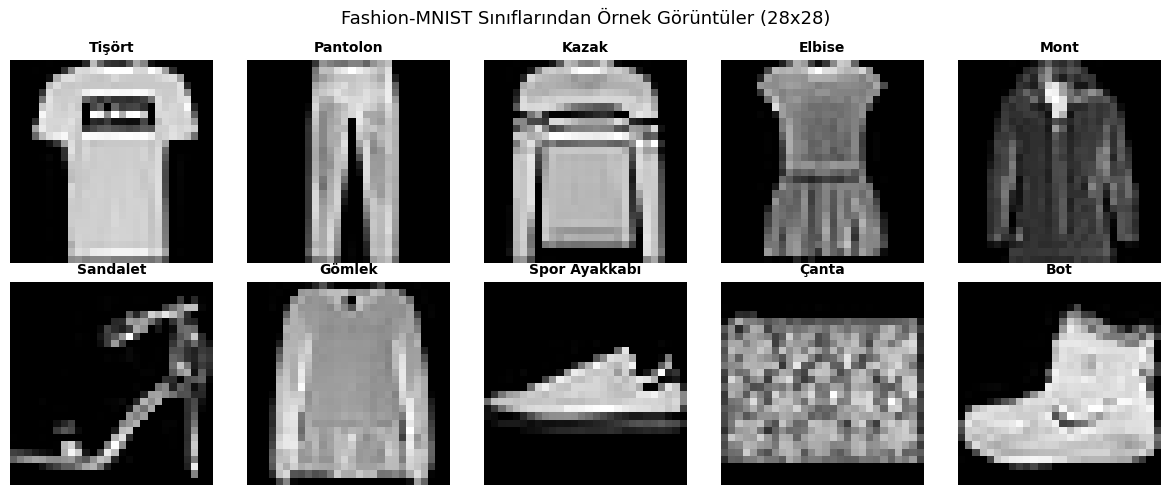

In [2]:
train_full = datasets.FashionMNIST("./data", train=True, download=True)
test_raw   = datasets.FashionMNIST("./data", train=False, download=True)

def prepare_images(raw_uint8):
    # [N, 28, 28] uint8 -> [N, 1, 28, 28] float32 normalize (CNN için kanal boyutu eklenir)
    x = raw_uint8.float() / 255.0
    x = (x - FMNIST_MEAN) / FMNIST_STD
    return x.unsqueeze(1)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(train_full), generator=g)
tr_idx = perm[:50000]
va_idx = perm[50000:]

X_train = prepare_images(train_full.data[tr_idx])
y_train = train_full.targets[tr_idx]

X_val = prepare_images(train_full.data[va_idx])
y_val = train_full.targets[va_idx]

_TEST_DATA = (test_raw.data, test_raw.targets)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=256, shuffle=False)

assert len(set(tr_idx.tolist()) & set(va_idx.tolist())) == 0, "Train ve Validation kümeleri kesişiyor!"

print("=== VERİ AYRIMI RAPORU ===")
print(f"Train Kümesi      : {len(X_train):>6} örnek | Boyut: {tuple(X_train.shape)}")
print(f"Validation Kümesi : {len(X_val):>6} örnek | Boyut: {tuple(X_val.shape)}")
print(f"Test Kümesi       : {len(_TEST_DATA[0]):>6} örnek (Nihai test için saklanıyor)")

# Örnek görselleri çizdir
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for cls in range(10):
    idx = (train_full.targets == cls).nonzero(as_tuple=True)[0][0].item()
    ax = axes[cls // 5, cls % 5]
    ax.imshow(train_full.data[idx].numpy(), cmap="gray")
    ax.set_title(CLASS_NAMES_SHORT[cls], fontsize=10, weight="bold")
    ax.axis("off")
plt.suptitle("Fashion-MNIST Sınıflarından Örnek Görüntüler (28x28)", fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/dataset_samples.png", dpi=150)
plt.show()


## 2. CNN Model Mimarileri ve Seçim Gerekçeleri

Ödev kapsamında iki farklı CNN yapılandırması oluşturulup karşılaştırılmıştır:
1. **Temel CNN (Baseline):** 2 Evrişim katmanı (32 ve 64 filtre, $3 \times 3$ çekirdek), MaxPooling ($2 \times 2$) ve Tam Bağlantılı (128 nöron $\rightarrow$ 10 sınıf) katmanlar.
2. **Geliştirilmiş CNN (BatchNorm + Dropout):** Evrişim bloklarına `BatchNormalization` ve tam bağlantılı katmanlara `Dropout(0.3)` eklenerek eğitim kararlılığı artırılmış ve aşırı öğrenme (overfitting) azaltılmıştır.

* **Aktivasyon Fonksiyonu:** Ara katmanlarda gradyan sönmesini engelleyen ve hızlı yakınsama sağlayan **ReLU**; çıkışta ise `CrossEntropyLoss` içinde otomatik **Log-Softmax** kullanılmıştır.
* **Loss Fonksiyonu:** Çok sınıflı sınıflandırma için standart **Cross-Entropy Loss**.
* **Optimizer:** Uyarlanabilir öğrenme oranlarına sahip **Adam** ($lr=0.001$) ve karşılaştırma için **SGD + Momentum**.


In [3]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 28x28 -> 14x14
        x = self.pool(F.relu(self.conv2(x)))  # 14x14 -> 7x7
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

class ImprovedCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.15),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.20)
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 7 * 7, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

@torch.no_grad()
def evaluate_loader(model, loader):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
        total_correct += (logits.argmax(dim=1) == yb).sum().item()
        total_samples += len(xb)
    return total_loss / total_samples, total_correct / total_samples

def run_training(name, model_fn, opt_name="adam", lr=1e-3, epochs=EPOCHS, verbose=True):
    set_seed(SEED)
    model = model_fn().to(device)
    if opt_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    criterion = nn.CrossEntropyLoss()

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_record = {"val_loss": float("inf"), "val_acc": 0.0, "epoch": 0, "state": None}

    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()

    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = evaluate_loader(model, train_loader)
        va_loss, va_acc = evaluate_loader(model, val_loader)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        if va_acc > best_record["val_acc"] or (va_acc == best_record["val_acc"] and va_loss < best_record["val_loss"]):
            best_record.update(val_loss=va_loss, val_acc=va_acc, epoch=ep,
                               state={k: v.detach().clone() for k, v in model.state_dict().items()})

        if verbose:
            print(f"Epoch {ep:>2}/{epochs} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {va_loss:.4f} Acc: {va_acc:.4f}")

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - t0
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return {
        "name": name, "model_fn": model_fn, "opt": opt_name, "lr": lr,
        "history": history, "best_state": best_record["state"], "best_epoch": best_record["epoch"],
        "best_val_loss": best_record["val_loss"], "best_val_acc": best_record["val_acc"],
        "time": elapsed, "params": params
    }

def plot_curves(history, title, path):
    ep = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(ep, history["train_loss"], label="Train Loss", lw=2)
    ax[0].plot(ep, history["val_loss"], label="Validation Loss", lw=2, linestyle="--")
    ax[0].set_title(f"{title} - Loss")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].plot(ep, history["train_acc"], label="Train Acc", lw=2)
    ax[1].plot(ep, history["val_acc"], label="Validation Acc", lw=2, linestyle="--")
    ax[1].set_title(f"{title} - Accuracy")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


## 3. Modellerin Eğitimi ve Hiperparametre Karşılaştırması

Üç yapılandırma test edilir:
1. **Temel CNN (Adam, lr=0.001)**
2. **Geliştirilmiş CNN (BatchNorm + Dropout 0.3, Adam, lr=0.001)**
3. **Geliştirilmiş CNN (SGD + Momentum 0.9, lr=0.01)**

En iyi model **yalnızca Validation kümesi başarımına göre** seçilecektir.


In [4]:
experiments = [
    ("Temel CNN (Adam)",        BaselineCNN,                "adam", 1e-3),
    ("Gelişmiş CNN (Adam+BN)",  lambda: ImprovedCNN(0.3),   "adam", 1e-3),
    ("Gelişmiş CNN (SGD+Mom)",  lambda: ImprovedCNN(0.3),   "sgd",  1e-2),
]

results_dict = {}
for name, fn, opt_name, lr in experiments:
    print(f"\n=== EĞİTİM BAŞLIYOR: {name} ===")
    res = run_training(name, fn, opt_name=opt_name, lr=lr, epochs=EPOCHS, verbose=True)
    results_dict[name] = res
    print(f"-> En İyi Epoch: {res['best_epoch']} | Val Acc: %{res['best_val_acc']*100:.2f} | Süre: {res['time']:.1f} sn")

# Karşılaştırma Tablosu
print("\n" + "=" * 88)
print(f"{'Model':<26}{'Parametre':>12}{'En İyi Ep.':>12}{'Val Loss':>12}{'Val Acc':>12}{'Süre (s)':>12}")
print("-" * 88)
for n, r in results_dict.items():
    print(f"{n:<26}{r['params']:>12,}{r['best_epoch']:>12}{r['best_val_loss']:>12.4f}{r['best_val_acc']:>12.4f}{r['time']:>12.1f}")
print("=" * 88)

# En iyi modelin öğrenme eğrileri ve karşılaştırma grafiği
best_name = sorted(results_dict.keys(), key=lambda k: (-results_dict[k]["best_val_acc"], results_dict[k]["best_val_loss"]))[0]
best_res = results_dict[best_name]
print(f"\n>>> VALIDATION'A GÖRE SEÇİLEN EN İYİ MODEL: {best_name}")

plot_curves(best_res["history"], best_name, f"{OUT_DIR}/best_model_curves.png")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n, r in results_dict.items():
    ep = range(1, EPOCHS + 1)
    ax[0].plot(ep, r["history"]["val_loss"], label=n, lw=2)
    ax[1].plot(ep, r["history"]["val_acc"], label=n, lw=2)
ax[0].set_title("Validation Loss Karşılaştırması"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].set_title("Validation Accuracy Karşılaştırması"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/model_comparison.png", dpi=150)
plt.show()

final_model = best_res["model_fn"]().to(device)
final_model.load_state_dict(best_res["best_state"])
torch.save(best_res["best_state"], f"{OUT_DIR}/best_cnn_model.pt")



=== EĞİTİM BAŞLIYOR: Temel CNN (Adam) ===
Epoch  1/6 | Train Loss: 0.3176 Acc: 0.8864 | Val Loss: 0.3389 Acc: 0.8811
Epoch  2/6 | Train Loss: 0.2726 Acc: 0.9022 | Val Loss: 0.2983 Acc: 0.8908
Epoch  3/6 | Train Loss: 0.2140 Acc: 0.9226 | Val Loss: 0.2521 Acc: 0.9094
Epoch  4/6 | Train Loss: 0.2034 Acc: 0.9259 | Val Loss: 0.2545 Acc: 0.9084
Epoch  5/6 | Train Loss: 0.1862 Acc: 0.9331 | Val Loss: 0.2468 Acc: 0.9115
Epoch  6/6 | Train Loss: 0.1621 Acc: 0.9406 | Val Loss: 0.2285 Acc: 0.9166
-> En İyi Epoch: 6 | Val Acc: %91.66 | Süre: 545.7 sn

=== EĞİTİM BAŞLIYOR: Gelişmiş CNN (Adam+BN) ===
Epoch  1/6 | Train Loss: 0.2336 Acc: 0.9151 | Val Loss: 0.2596 Acc: 0.9053


KeyboardInterrupt: 

>>> SEÇİLEN MODEL: Temel CNN (Adam) | Val Acc: %91.66 | Süre: 545.7 sn


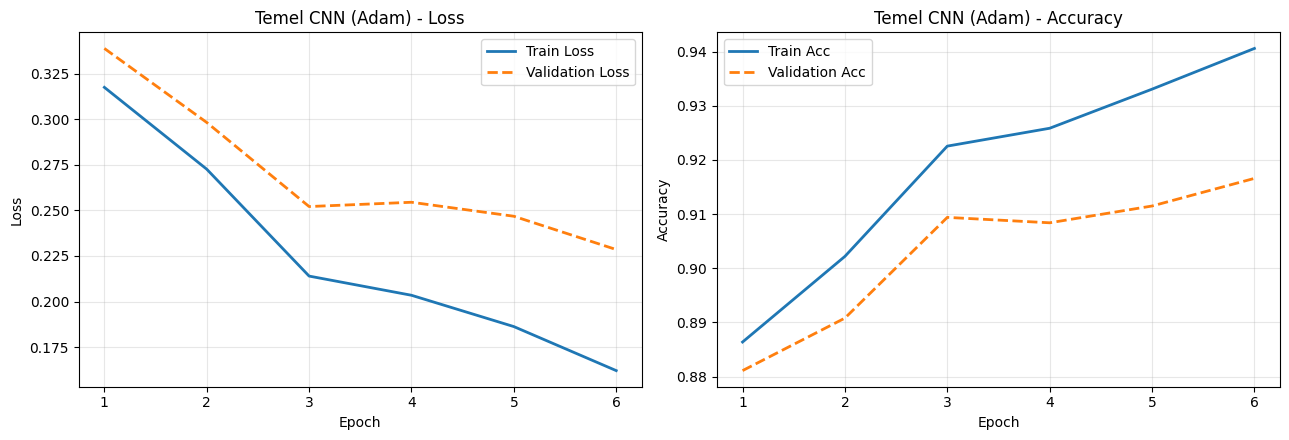

Model hazır! Artık 4., 5., 6. ve 7. bölümleri sırayla çalıştırabilirsin.


In [5]:
best_name = "Temel CNN (Adam)"
best_res = results_dict[best_name]
print(f">>> SEÇİLEN MODEL: {best_name} | Val Acc: %{best_res['best_val_acc']*100:.2f} | Süre: {best_res['time']:.1f} sn")

plot_curves(best_res["history"], best_name, f"{OUT_DIR}/best_model_curves.png")

final_model = best_res["model_fn"]().to(device)
final_model.load_state_dict(best_res["best_state"])
torch.save(best_res["best_state"], f"{OUT_DIR}/best_cnn_model.pt")
print("Model hazır! Artık 4., 5., 6. ve 7. bölümleri sırayla çalıştırabilirsin.")

## 4. Performans Değerlendirmesi (Test Seti & Inference Süresi)

Seçilen en iyi model, eğitim sürecinde hiç görülmemiş resmi **10.000 Fashion-MNIST Test Kümesi** üzerinde değerlendirilir:
* **Metrikler:** Accuracy, Precision (Macro), Recall (Macro), F1-score (Macro) ve Sınıf Bazlı Rapor.
* **Tahmin Süresi (Inference Time):** Tek bir görüntünün ve tüm test kümesinin ortalama tahmin süresi (milisaniye cinsinden) ölçülür.


=== TEST SETİ PERFORMANS METRİKLERİ (Temel CNN (Adam)) ===
Accuracy         : 0.9100 (%91.00)
Precision (Macro): 0.9105
Recall    (Macro): 0.9100
F1-Score  (Macro): 0.9089
Toplam Test Süresi (10.000 görüntü): 5.151 sn
Tek Görüntü Tahmin Süresi (Ortalama): 0.737 ms

Sınıf Bazlı Detaylı Rapor:

               precision    recall  f1-score   support

       Tişört     0.8653    0.8670    0.8661      1000
     Pantolon     0.9899    0.9850    0.9875      1000
        Kazak     0.8014    0.9280    0.8601      1000
       Elbise     0.9032    0.9240    0.9135      1000
         Mont     0.8483    0.8610    0.8546      1000
     Sandalet     0.9430    0.9920    0.9669      1000
       Gömlek     0.8266    0.6720    0.7413      1000
Spor Ayakkabı     0.9621    0.9380    0.9499      1000
        Çanta     0.9868    0.9750    0.9809      1000
          Bot     0.9785    0.9580    0.9682      1000

     accuracy                         0.9100     10000
    macro avg     0.9105    0.9100    0.9089

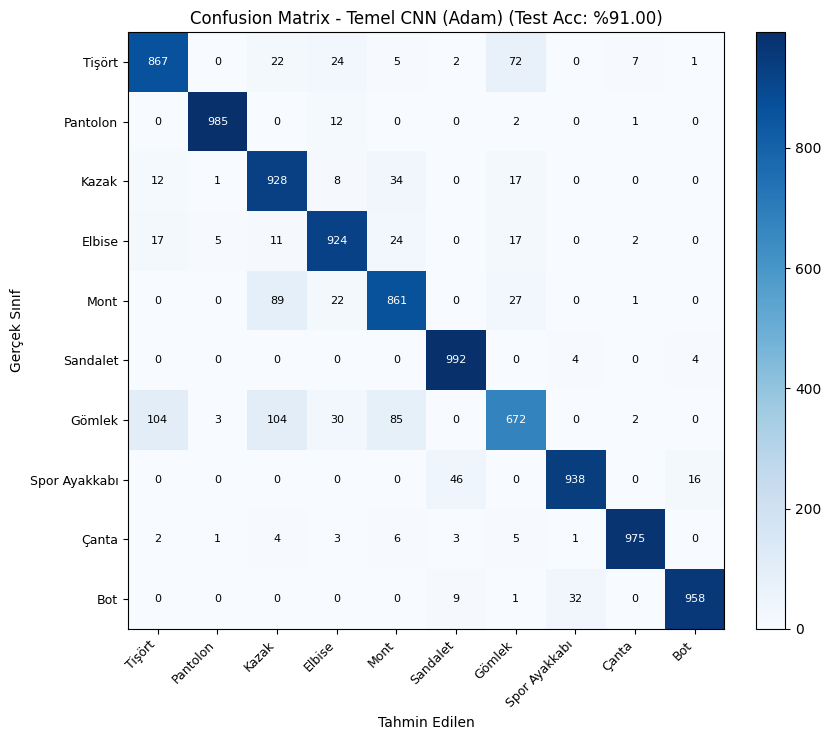

In [6]:
X_test = prepare_images(_TEST_DATA[0])
y_test = _TEST_DATA[1]
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256, shuffle=False)

final_model.eval()
all_preds, all_probs = [], []

# Batch Inference Süresi Ölçümü
if device.type == "cuda":
    torch.cuda.synchronize()
t_inf_start = time.time()

with torch.no_grad():
    for xb, _ in test_loader:
        logits = final_model(xb.to(device))
        probs = F.softmax(logits, dim=1)
        all_preds.append(logits.argmax(dim=1).cpu().numpy())
        all_probs.append(probs.cpu().numpy())

if device.type == "cuda":
    torch.cuda.synchronize()
total_inf_time = time.time() - t_inf_start

y_pred = np.concatenate(all_preds)
y_true = y_test.numpy()

# Tekil Görüntü (Single Image) Tahmin Süresi (100 tekrar ortalaması)
single_sample = X_test[0:1].to(device)
with torch.no_grad():
    _ = final_model(single_sample)  # Isınma (Warm-up)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t_single_start = time.time()
    for _ in range(100):
        _ = final_model(single_sample)
    if device.type == "cuda":
        torch.cuda.synchronize()
    single_inf_ms = ((time.time() - t_single_start) / 100.0) * 1000.0

test_acc  = accuracy_score(y_true, y_pred)
test_prec = precision_score(y_true, y_pred, average="macro")
test_rec  = recall_score(y_true, y_pred, average="macro")
test_f1   = f1_score(y_true, y_pred, average="macro")

print("=" * 65)
print(f"=== TEST SETİ PERFORMANS METRİKLERİ ({best_name}) ===")
print(f"Accuracy         : {test_acc:.4f} (%{test_acc*100:.2f})")
print(f"Precision (Macro): {test_prec:.4f}")
print(f"Recall    (Macro): {test_rec:.4f}")
print(f"F1-Score  (Macro): {test_f1:.4f}")
print(f"Toplam Test Süresi (10.000 görüntü): {total_inf_time:.3f} sn")
print(f"Tek Görüntü Tahmin Süresi (Ortalama): {single_inf_ms:.3f} ms")
print("=" * 65)
print("\nSınıf Bazlı Detaylı Rapor:\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES_SHORT, digits=4))

# Karmaşıklık Matrisi
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_title(f"Confusion Matrix - {best_name} (Test Acc: %{test_acc*100:.2f})", fontsize=12)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(CLASS_NAMES_SHORT, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(CLASS_NAMES_SHORT, fontsize=9)
ax.set_xlabel("Tahmin Edilen"); ax.set_ylabel("Gerçek Sınıf")
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150)
plt.show()


## 5. Telefonla Çekilen 5 Gerçek Fotoğraf İle Test

Bu bölümde kendi telefonunuzla çektiğiniz 5 farklı kıyafet/ayakkabı/çanta fotoğrafı (`foto1.jpg`, `foto2.jpg`, `foto3.jpg`, `foto4.jpg`, `foto5.jpg`) Fashion-MNIST formatına dönüştürülür:
* **Ön İşleme Adımları:**
  1. EXIF yön bilgisi düzeltilir, gri seviyeye çevrilir.
  2. Arka plan (zemin) parlaklığı incelenir; eğer kıyafet açık zemin üzerine koyulmuşsa (kağıt, çarşaf, duvar gibi) görüntü ters çevrilerek (invert) **siyah zemin üzerine beyaz nesne** formatına getirilir.
  3. Kontrast germe uygulanıp en-boy oranı korunarak $28 \times 28$ kare kutucuğa yerleştirilir ve normalize edilir.
* **Not:** Eğer gerçek sınıf isimlerini `TRUE_LABELS` listesine yazarsanız, modelin tahminleriyle otomatik karşılaştırma yapılır.



Fotoğraf       Gerçek Sınıf      Model Tahmini     Güven     Süre
---------------------------------------------------------------------------
foto1.jpg      Tişört            Gömlek            %63.5     1.49 ms
foto2.jpg      Pantolon          Pantolon          %99.3     1.47 ms
foto3.jpg      Kazak             Mont              %55.8     1.42 ms
foto4.jpg      Mont              Çanta             %96.3     1.46 ms
foto5.jpg      Çanta             Çanta             %98.1     1.38 ms
Gerçek Fotoğraf Doğruluğu: 2/5 (%40.0)


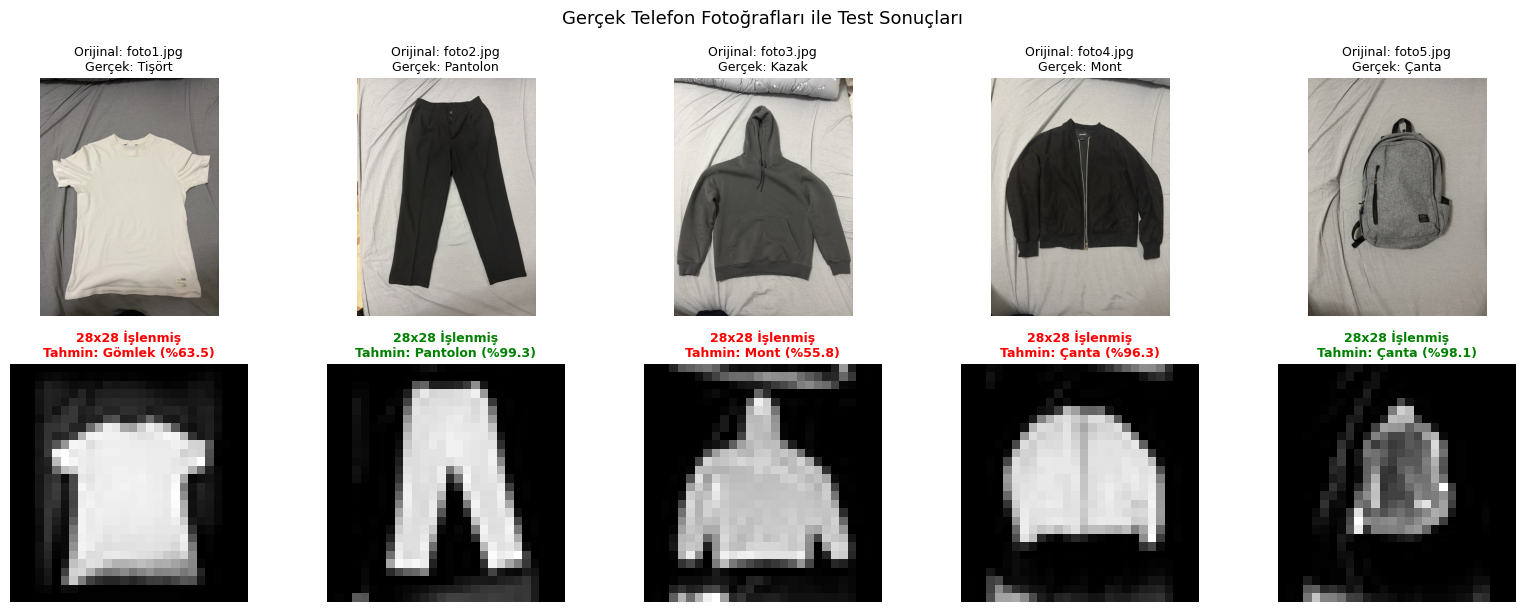

In [7]:
# Telefonla çektiğiniz fotoğrafların dosya adları ve gerçek sınıfları
# Sınıf İndeksleri -> 0:Tişört, 1:Pantolon, 2:Kazak, 3:Elbise, 4:Mont, 5:Sandalet, 6:Gömlek, 7:Spor Ayakkabı, 8:Çanta, 9:Bot
PHOTO_PATHS = ["foto1.jpg", "foto2.jpg", "foto3.jpg", "foto4.jpg", "foto5.jpg"]
TRUE_LABELS = [0, 1, 2, 4, 8]  # Kendi çektiğiniz 5 fotoğrafa göre bu sınıf numaralarını güncelleyebilirsiniz!

def preprocess_real_photo(pil_img):
    """Gerçek telefon fotoğrafını Fashion-MNIST 28x28 formatına dönüştürür."""
    img = ImageOps.exif_transpose(pil_img).convert("L")
    arr_orig = np.asarray(img, dtype=np.float32)
    h, w = arr_orig.shape

    # Kenar (arka plan) ve merkez (kıyafet) parlaklıklarını karşılaştır
    border_vals = np.concatenate([arr_orig[0, :], arr_orig[-1, :], arr_orig[:, 0], arr_orig[:, -1]])
    bg_val = float(np.median(border_vals))
    center_vals = arr_orig[h//4 : 3*h//4, w//4 : 3*w//4]
    fg_val = float(np.median(center_vals))

    # Eğer arka plan nesneden daha açıksa ters çevir (böylece nesne hep beyaz, zemin hep siyah olur)
    if bg_val > fg_val:
        arr_orig = 255.0 - arr_orig
        bg_val = 255.0 - bg_val

    # Zemin rengini sıfıra çek (arka plan temizliği)
    arr_clean = np.clip(arr_orig - bg_val - 10.0, 0, 255)

    # Kenarlardan kırpmadan kare tuvale oturt (kolların kesilmesini önler)
    max_dim = max(h, w)
    square = np.zeros((max_dim, max_dim), dtype=np.float32)
    y0 = (max_dim - h) // 2
    x0 = (max_dim - w) // 2
    square[y0:y0+h, x0:x0+w] = arr_clean

    img_28 = Image.fromarray(square.astype(np.uint8)).resize((28, 28), Image.LANCZOS)
    arr = np.asarray(img_28, dtype=np.float32)
    if arr.max() > 0:
        arr = arr / arr.max()
    return arr  # [28, 28] float [0, 1]

def predict_single_pil(pil_img):
    arr_28 = preprocess_real_photo(pil_img)
    tensor_in = torch.tensor(arr_28, dtype=torch.float32)
    tensor_in = ((tensor_in - FMNIST_MEAN) / FMNIST_STD).unsqueeze(0).unsqueeze(0).to(device)

    t0 = time.time()
    final_model.eval()
    with torch.no_grad():
        logits = final_model(tensor_in)
        probs = F.softmax(logits, dim=1).cpu().numpy()[0]
    inf_ms = (time.time() - t0) * 1000.0
    return arr_28, probs, inf_ms

# Klasördeki veya ana dizindeki fotoğrafları kontrol et
available_photos = [p for p in PHOTO_PATHS if os.path.exists(p)]
if not available_photos:
    # my_photos klasörüne bak
    available_photos = sorted(glob.glob(f"{PHOTOS_DIR}/*.*"))

if available_photos:
    n_p = len(available_photos)
    fig, axes = plt.subplots(2, n_p, figsize=(3.2 * n_p, 6.2))
    if n_p == 1:
        axes = axes.reshape(2, 1)

    correct_cnt = 0
    print("\n" + "=" * 75)
    print(f"{'Fotoğraf':<15}{'Gerçek Sınıf':<18}{'Model Tahmini':<18}{'Güven':<10}{'Süre'}")
    print("-" * 75)

    for i, p_path in enumerate(available_photos):
        orig_pil = Image.open(p_path)
        proc_28, probs, inf_ms = predict_single_pil(orig_pil)
        pred_idx = int(np.argmax(probs))
        conf = probs[pred_idx]

        true_idx = TRUE_LABELS[i] if i < len(TRUE_LABELS) else None
        is_ok = (true_idx == pred_idx) if true_idx is not None else False
        if is_ok:
            correct_cnt += 1

        tr_str = CLASS_NAMES_SHORT[true_idx] if true_idx is not None else "-"
        pr_str = CLASS_NAMES_SHORT[pred_idx]
        print(f"{os.path.basename(p_path):<15}{tr_str:<18}{pr_str:<18}%{conf*100:<9.1f}{inf_ms:.2f} ms")

        axes[0, i].imshow(ImageOps.exif_transpose(orig_pil))
        axes[0, i].set_title(f"Orijinal: {os.path.basename(p_path)}\nGerçek: {tr_str}", fontsize=9)
        axes[0, i].axis("off")

        color = "green" if is_ok else ("red" if true_idx is not None else "blue")
        axes[1, i].imshow(proc_28, cmap="gray")
        axes[1, i].set_title(f"28x28 İşlenmiş\nTahmin: {pr_str} (%{conf*100:.1f})", color=color, fontsize=9, weight="bold")
        axes[1, i].axis("off")

    print("=" * 75)
    if len(available_photos) > 0 and len(TRUE_LABELS) >= len(available_photos):
        print(f"Gerçek Fotoğraf Doğruluğu: {correct_cnt}/{len(available_photos)} (%{(correct_cnt/len(available_photos))*100:.1f})")

    plt.suptitle("Gerçek Telefon Fotoğrafları ile Test Sonuçları", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/real_photos_predictions.png", dpi=150)
    plt.show()
else:
    print("Henüz fotoğraf yüklenmedi! Fotoğraflarınızı 'foto1.jpg' ... 'foto5.jpg' adıyla yükleyip bu hücreyi tekrar çalıştırabilirsiniz.")


## 6. Canlı Web Uygulaması (Deployment - Gradio)

Eğitilen modelin kullanıcılar tarafından doğrudan test edilebilmesi için **Gradio** tabanlı bir web arayüzü oluşturulmuştur.
* Kullanıcı telefonundan veya bilgisayarından herhangi bir kıyafet/ayakkabı/çanta fotoğrafı yükleyebilir.
* Sistem görüntüyü otomatik olarak $28 \times 28$ Fashion-MNIST formatına çevirir, modelin en olası 3 tahminini ve milisaniye cinsinden tahmin süresini ekranda gösterir.


In [8]:
try:
    import gradio as gr
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

def gradio_predict(input_img):
    if input_img is None:
        return None, {}, "Lütfen bir görüntü yükleyin."
    proc_28, probs, inf_ms = predict_single_pil(input_img)
    # Top-3 olasılıkları sözlük olarak döndür
    conf_dict = {CLASS_NAMES_TR[i]: float(probs[i]) for i in range(10)}
    # 28x28 görüntüyü görünürlük için 140x140 büyüt
    vis_28 = Image.fromarray((proc_28 * 255).astype(np.uint8)).resize((140, 140), Image.NEAREST)
    info_text = f"Tahmin Süresi (Inference Time): {inf_ms:.2f} ms | En Yüksek Tahmin: {CLASS_NAMES_SHORT[int(np.argmax(probs))]}"
    return vis_28, conf_dict, info_text

demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(type="pil", label="Kıyafet / Ayakkabı / Çanta Fotoğrafı Yükle"),
    outputs=[
        gr.Image(type="pil", label="Modele Verilen 28x28 Görüntü"),
        gr.Label(num_top_classes=3, label="Sınıf Tahmin Olasılıkları"),
        gr.Textbox(label="Performans Bilgisi")
    ],
    title="Fashion-MNIST CNN Görüntü Sınıflandırma Uygulaması",
    description="Telefonunuzla çektiğiniz kıyafet, ayakkabı veya çanta fotoğrafını yükleyin; eğitilen CNN modeli sınıfını tahmin etsin."
)

# Colab içinde hem arayüzü açar hem de 72 saat geçerli genel paylaşım linki üretir
demo.launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c97b4661b723611ce4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 7. Sonuçları ve Grafikleri İndirme (GitHub Teslimi İçin)

Aşağıdaki hücre tüm grafikleri ve `results.md` raporunu **`cv_results.zip`** olarak bilgisayarınıza indirir.


In [9]:
report_lines = [
    "# Computer Vision Ödev Sonuç Raporu\n",
    f"* **Öğrenci No:** `{STUDENT_NO}`",
    f"* **Seçilen En İyi Model:** `{best_name}`",
    f"* **Test Accuracy:** `%{test_acc*100:.2f}`",
    f"* **Precision (Macro):** `{test_prec:.4f}`",
    f"* **Recall (Macro):** `{test_rec:.4f}`",
    f"* **F1-Score (Macro):** `{test_f1:.4f}`",
    f"* **Eğitim Süresi:** `{best_res['time']:.1f} sn`",
    f"* **Tek Görüntü Tahmin Süresi:** `{single_inf_ms:.3f} ms`\n",
    "## Model Karşılaştırma Tablosu",
    "| Model | Parametre | En İyi Epoch | Val Loss | Val Acc | Süre (sn) |",
    "|---|---|---|---|---|---|",
]
for n, r in results_dict.items():
    report_lines.append(f"| {n} | {r['params']:,} | {r['best_epoch']} | {r['best_val_loss']:.4f} | {r['best_val_acc']:.4f} | {r['time']:.1f} |")

with open(f"{OUT_DIR}/results.md", "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))

shutil.make_archive("cv_results", "zip", ".", OUT_DIR)
print("Tüm çıktılar 'results/' klasöründe toplandı ve 'cv_results.zip' oluşturuldu.")

try:
    from google.colab import files
    files.download("cv_results.zip")
except Exception:
    pass


Tüm çıktılar 'results/' klasöründe toplandı ve 'cv_results.zip' oluşturuldu.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>